In [1]:
# Cell 1: Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load dataset
# Assuming the file is named 'car_data.csv'
df = pd.read_csv('cardekho.csv')
display(df.head())

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78,5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.2,5.0


In [2]:
# Check for null values
print("Null values before cleaning:\n", df.isnull().sum())

# 1. Handle missing values
df.dropna(inplace=True)

# 2. Remove duplicates
df.drop_duplicates(inplace=True)

# 3. Address inconsistent categorical values 
if 'Fuel_Type' in df.columns:
    df['Fuel_Type'] = df['Fuel_Type'].str.lower().str.strip()

if 'Transmission' in df.columns:
    df['Transmission'] = df['Transmission'].str.lower().str.strip()
    
print(f"Dataset shape after cleaning: {df.shape}")

Null values before cleaning:
 name                    0
year                    0
selling_price           0
km_driven               0
fuel                    0
seller_type             0
transmission            0
owner                   0
mileage(km/ltr/kg)    221
engine                221
max_power             215
seats                 221
dtype: int64
Dataset shape after cleaning: (6718, 12)


In [3]:
# Check for null values
print("Null values before cleaning:\n", df.isnull().sum())

# 1. Handle missing values
# Fill missing numerical values with the mean
numeric_cols = df.select_dtypes(include=['number']).columns
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].mean())

# Fill missing categorical (text) values with the mode (most frequent value)
categorical_cols = df.select_dtypes(include=['object']).columns
for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# 2. Remove duplicates
df.drop_duplicates(inplace=True)

# 3. Address inconsistent categorical values 
if 'Fuel_Type' in df.columns:
    df['Fuel_Type'] = df['Fuel_Type'].str.lower().str.strip()

if 'Transmission' in df.columns:
    df['Transmission'] = df['Transmission'].str.lower().str.strip()
    
print(f"Dataset shape after cleaning: {df.shape}")

Null values before cleaning:
 name                  0
year                  0
selling_price         0
km_driven             0
fuel                  0
seller_type           0
transmission          0
owner                 0
mileage(km/ltr/kg)    0
engine                0
max_power             0
seats                 0
dtype: int64
Dataset shape after cleaning: (6718, 12)


C:\Users\dell\AppData\Local\Temp\ipykernel_9692\4013342201.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=['object']).columns


In [4]:
# Calculate car age (Using 2024 as the baseline year for the dataset)
current_year = 2024 
if 'Year' in df.columns:
    df['Car_Age'] = current_year - df['Year']

# Extract brand from car name 
if 'Car_Name' in df.columns:
    df['Brand'] = df['Car_Name'].apply(lambda x: str(x).split()[0].title())

display(df.head())

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78,5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.2,5.0


In [5]:
# Calculate car age (Using 2024 as the baseline year)
current_year = 2024 
if 'year' in df.columns:
    df['Car_Age'] = current_year - df['year']

# Extract brand from car name 
if 'name' in df.columns:
    df['Brand'] = df['name'].apply(lambda x: str(x).split()[0].title())

# Print the column names to confirm the new features were added
print("Current columns in the dataset:")
print(df.columns.tolist())

display(df.head())

Current columns in the dataset:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage(km/ltr/kg)', 'engine', 'max_power', 'seats', 'Car_Age', 'Brand']


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats,Car_Age,Brand
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74,5.0,10,Maruti
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5.0,10,Skoda
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78,5.0,18,Honda
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90,5.0,14,Hyundai
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.2,5.0,17,Maruti


In [6]:
# Drop the original 'name' and 'year' columns now that we have 'Brand' and 'Car_Age'
columns_to_drop = []
if 'name' in df.columns:
    columns_to_drop.append('name')
if 'year' in df.columns:
    columns_to_drop.append('year')

# Removed axis=1 to resolve the ValueError
df.drop(columns=columns_to_drop, inplace=True, errors='ignore')
display(df.head())

,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats,Car_Age,Brand
0,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74,5.0,10,Maruti
1,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5.0,10,Skoda
2,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78,5.0,18,Honda
3,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90,5.0,14,Hyundai
4,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.2,5.0,17,Maruti


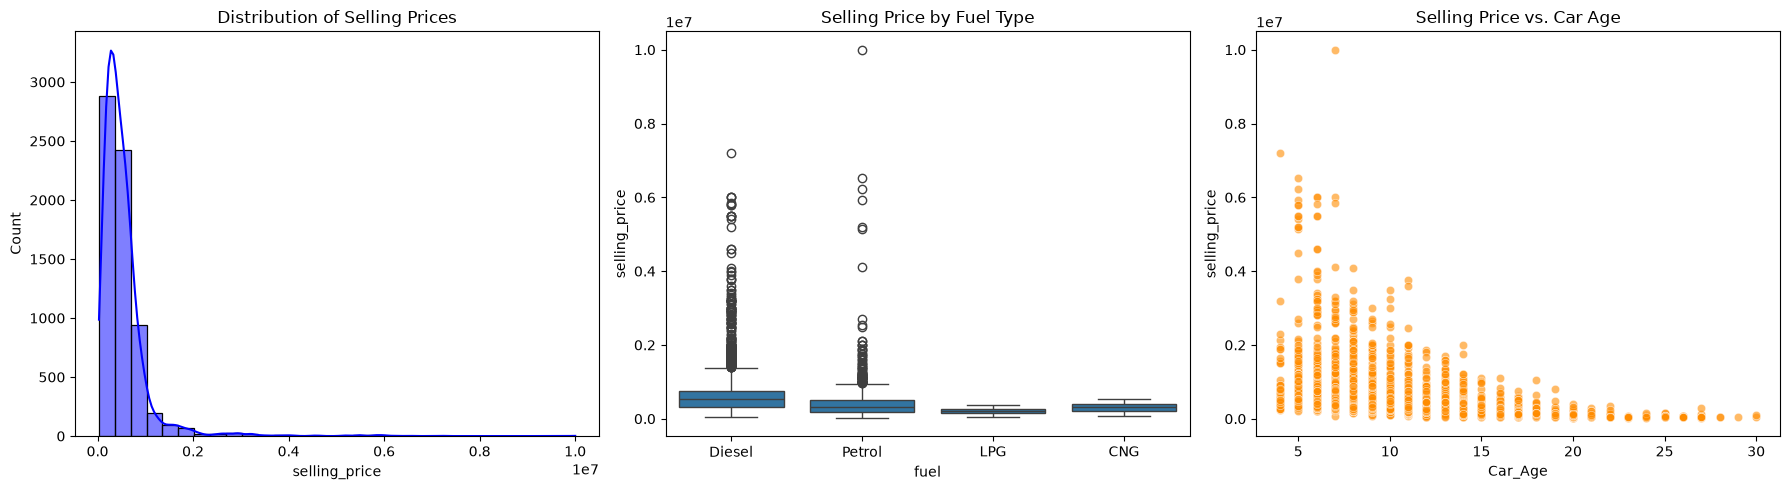

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(18, 5))

# 1. Distribution of selling prices
plt.subplot(1, 3, 1)
sns.histplot(df['selling_price'], kde=True, bins=30, color='blue')
plt.title('Distribution of Selling Prices')

# 2. Price vs. Fuel Type Box Plot
plt.subplot(1, 3, 2)
sns.boxplot(x='fuel', y='selling_price', data=df)
plt.title('Selling Price by Fuel Type')

# 3. Price vs. Car Age Scatter Plot
plt.subplot(1, 3, 3)
sns.scatterplot(x='Car_Age', y='selling_price', data=df, alpha=0.6, color='darkorange')
plt.title('Selling Price vs. Car Age')

plt.tight_layout()
plt.show()

In [8]:
# Select all remaining text columns
categorical_cols = df.select_dtypes(include=['object']).columns

# Apply One-Hot Encoding (drop_first=True helps prevent multicollinearity)
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

print(f"Shape after encoding: {df_encoded.shape}")
display(df_encoded.head())

Shape after encoding: (6718, 364)


C:\Users\dell\AppData\Local\Temp\ipykernel_9692\1048091038.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=['object']).columns


,selling_price,km_driven,mileage(km/ltr/kg),engine,seats,Car_Age,fuel_Diesel,fuel_LPG,fuel_Petrol,seller_type_Individual,...,Brand_Mg,Brand_Mitsubishi,Brand_Nissan,Brand_Opel,Brand_Renault,Brand_Skoda,Brand_Tata,Brand_Toyota,Brand_Volkswagen,Brand_Volvo
0,450000,145500,23.40,1248.0,5.0,10,True,False,False,True,...,False,False,False,False,False,False,False,False,False,False
1,370000,120000,21.14,1498.0,5.0,10,True,False,False,True,...,False,False,False,False,False,True,False,False,False,False
2,158000,140000,17.70,1497.0,5.0,18,False,False,True,True,...,False,False,False,False,False,False,False,False,False,False
3,225000,127000,23.00,1396.0,5.0,14,True,False,False,True,...,False,False,False,False,False,False,False,False,False,False
4,130000,120000,16.10,1298.0,5.0,17,False,False,True,True,...,False,False,False,False,False,False,False,False,False,False


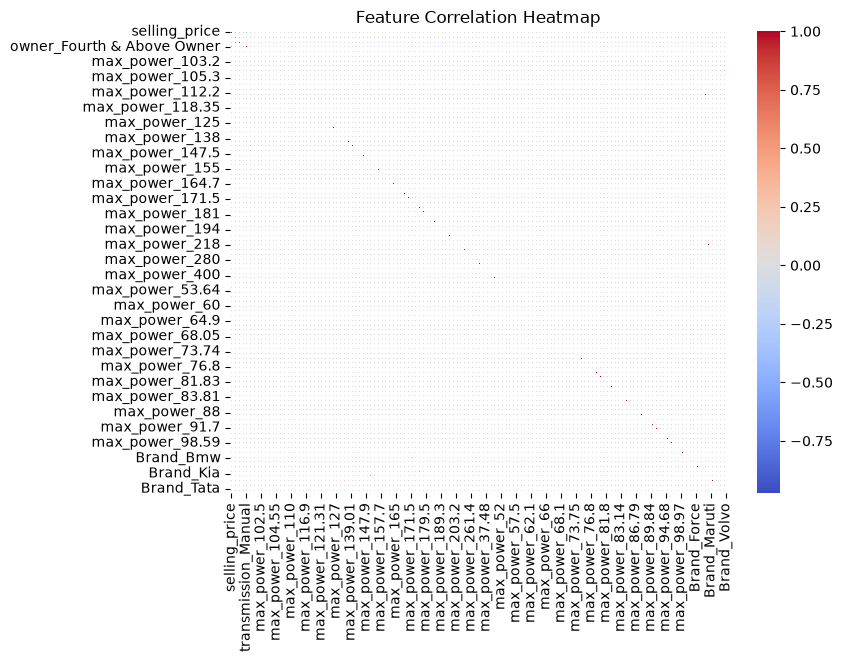

In [9]:
plt.figure(figsize=(8, 6))
# Calculate correlations
corr_matrix = df_encoded.corr()

# Plot heatmap (annot=False keeps it clean if there are many columns)
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', linewidths=0.5)
plt.title('Feature Correlation Heatmap')
plt.show()

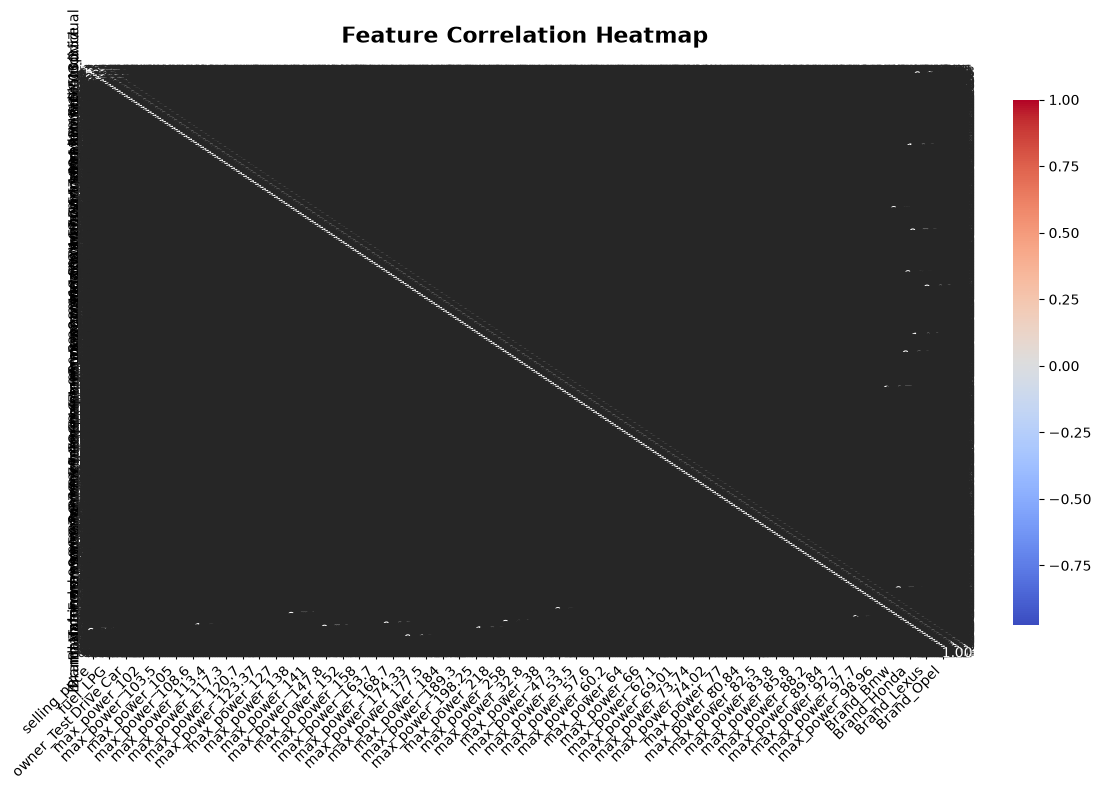

In [10]:
plt.figure(figsize=(12, 8))

# Calculate correlations
corr_matrix = df_encoded.corr()

# Plot the heatmap matching the requested style
sns.heatmap(corr_matrix, 
            annot=True,              # Show numbers inside cells
            fmt='.2f',               # Format numbers to 2 decimal places (e.g., 1.00, -0.12)
            cmap='coolwarm',         # Blue/White/Red color scale
            linewidths=1,            # Width of the lines dividing the cells
            linecolor='white',       # White lines between cells
            cbar_kws={'shrink': 0.9} # Slightly scale down the colorbar to match the image
           )

# Title with bold font
plt.title('Feature Correlation Heatmap', fontsize=16, fontweight='bold', pad=20)

# Rotate y-axis labels 90 degrees to match the vertical text in your image
plt.yticks(rotation=90, va='center')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

In [11]:
from sklearn.model_selection import train_test_split

# Separate features (X) and target (y)
X = df_encoded.drop('selling_price', axis=1)
y = df_encoded['selling_price']

# 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training features shape: {X_train.shape}")
print(f"Testing features shape: {X_test.shape}")

Training features shape: (5374, 363)
Testing features shape: (1344, 363)


In [12]:
def evaluate_model(true, predicted, model_name):
    mae = mean_absolute_error(true, predicted)
    rmse = np.sqrt(mean_squared_error(true, predicted))
    r2 = r2_score(true, predicted)
    print(f"--- {model_name} ---")
    print(f"MAE:  {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"R²:   {r2:.4f}\n")

# Model 1: Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_preds = lr_model.predict(X_test)
evaluate_model(y_test, lr_preds, "Linear Regression")

# Model 2: Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)
evaluate_model(y_test, rf_preds, "Random Forest Regressor")

--- Linear Regression ---
MAE:  132782.2724
RMSE: 208013.7931
R²:   0.7545

--- Random Forest Regressor ---
MAE:  78526.7091
RMSE: 152240.2067
R²:   0.8685



C:\Users\dell\AppData\Local\Temp\ipykernel_9692\4127167645.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis')


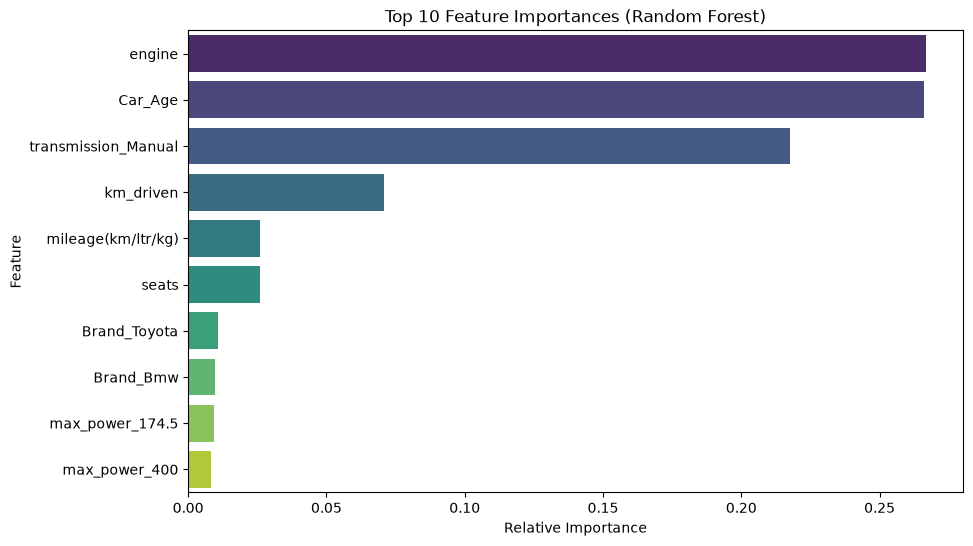

In [13]:
# Extract feature importances from the Random Forest model
importances = rf_model.feature_importances_
features = X.columns

# Sort and select the top 10 features
importance_df = pd.DataFrame({'Feature': features, 'Importance': importances})
importance_df = importance_df.sort_values(by='Importance', ascending=False).head(10)

# Plot the Feature Importance Chart
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis')
plt.title('Top 10 Feature Importances (Random Forest)')
plt.xlabel('Relative Importance')
plt.ylabel('Feature')
plt.show()